In [1]:
import poly_tools as pt
import numpy as np
import winding_GBZ_solver as wGs
import matplotlib.pyplot as plt
from numpy import sin, cos, exp, log, sqrt, pi, tan

PHCv2.4.90 released 2024-03-20 works!


In [2]:
Jx, Jy = np.random.randn(2) + 1j * np.random.randn(2)
delta_x, delta_y = np.random.rand(2) * 2 * np.pi
gamma_x, gamma_y = np.random.rand(2) + 0.5
Delta_xy = delta_x - delta_y

In [3]:
Jx1 = gamma_x * np.exp(1j * delta_x) * Jx
Jx2 = 1 / gamma_x * np.exp(1j * delta_x) * Jx.conjugate()
Jy1 = gamma_y * np.exp(1j * delta_y) * Jy
Jy2 = 1 / gamma_y * np.exp(1j * delta_y) * Jy.conjugate()

In [4]:
print(Jx, Jy)
print(delta_x / np.pi, delta_y / np.pi)
print(gamma_x, gamma_y)

(-0.5805438073987677-0.3494355951334079j) (-0.7564203624865851+0.08915971308433038j)
1.1981191181536432 0.8836123214151201
1.4433328448927338 1.3845340877531194


# x-strip and y-strip

In [5]:
def ChP_xy(E, betax, betay):
    return (
        E 
        - Jx1 / betax
        - Jx2 * betax
        - Jy1 / betay
        - Jy2 * betay
    )

In [6]:
def vxy(E, r, thetax):
    return (
        E * np.exp(-1j * delta_y)
        - np.exp(1j * Delta_xy) * (
            gamma_x * Jx / r * np.exp(-1j * thetax)
            + Jx.conjugate() * r * np.exp(1j * thetax) / gamma_x
        )
    )

def diff_vxy(E, r, thetax):
    ''' Derivative of vxy against thetax'''
    return np.exp(1j * Delta_xy) * (
        1j * gamma_x * Jx / r * np.exp(-1j * thetax)
        - 1j / gamma_x * Jx.conjugate() * r * np.exp(1j * thetax)
    )

In [7]:
def solve_beta_x(E, thetay):
    lhs = np.exp(1j * delta_y) * 2 * (
            Jy.conjugate() * np.exp(1j * thetay)
        ).real
    roots = np.roots(
        [Jx2, lhs - E, Jx1]
    )
    return roots

## Test derivative $\frac{d|\mathcal{B}_1|^2}{d\theta_1}$

In [8]:
E = np.random.randn() + 1j * np.random.randn()
thetay = np.random.rand() * 2 * np.pi

In [9]:
# Test root solving
roots = solve_beta_x(E, thetay)
for betax in roots:
    print(
        abs(ChP_xy(E, betax, gamma_y * np.exp(1j * thetay)))
    )

0.0
2.482534153247273e-16


In [10]:
# Test vxy
roots = solve_beta_x(E, thetay)
for betax in roots:
    r = abs(betax)
    thetax = np.log(betax).imag
    lhs = 2 * (Jy.conjugate() * np.exp(1j * thetay)).real
    print(abs(lhs - vxy(E, r, thetax)))
    dthetax = np.random.randn() * 1e-4
    v2 = vxy(E, r, thetax + dthetax)
    print(v2 - vxy(E, r, thetax))
    print(diff_vxy(E, r, thetax) * dthetax)
    print(abs(v2 - vxy(E, r, thetax) - diff_vxy(E, r, thetax) * dthetax))
    print()

2.220446049250313e-16
(7.443088536351894e-05+8.320226232427785e-05j)
(7.442938660390979e-05+8.320415385255544e-05j)
2.4133295653336268e-09

3.1401849173675503e-16
(-3.6619386400760234e-05-4.093745046085395e-05j)
(-3.6619749223118804e-05-4.093699259698481e-05j)
5.841912242937114e-10



In [11]:
# Test derivative
dtheta = np.random.randn() * 1e-3
# 1. Calculate betax for theta and theta + dtheta
betax1 = solve_beta_x(E, thetay)
betax2 = solve_beta_x(E, thetay + dtheta)

# 2. Match solutions by distance
distance_list = np.abs(betax2 - betax1[0])
if np.argmin(distance_list) == 0:
    pass
else:
    betax2 = betax2[::-1]

# 3. Calculate derivative for theta
derivative_list = np.zeros(2)
for point_ind in range(2):
    curr_betax = betax1[point_ind]
    curr_r = abs(curr_betax)
    curr_thetax = np.log(curr_betax).imag
    C = (2 * gamma_x ** 2 / (curr_r ** 2)
         / abs(
            gamma_x ** 2 * Jx / (curr_r ** 2) / curr_betax
            - Jx.conjugate() / curr_betax.conjugate()
           ) ** 2
        )
    thetay_term = (Jy * np.exp(-1j * thetay)).imag
    diff_term = diff_vxy(E, curr_r, curr_thetax).imag
    derivative_list[point_ind] = 2 * C * thetay_term * diff_term

# 4. Calculate numeric derivative
print(np.abs(betax2) ** 2 - np.abs(betax1) ** 2)
print(derivative_list * dtheta)
print(np.abs(betax2) ** 2 - np.abs(betax1) ** 2 - derivative_list * dtheta)

[-0.00585714  0.00022745]
[-0.00586065  0.00022746]
[ 3.51332287e-06 -1.03724960e-08]


## Test winding number

Jy charge 1.0


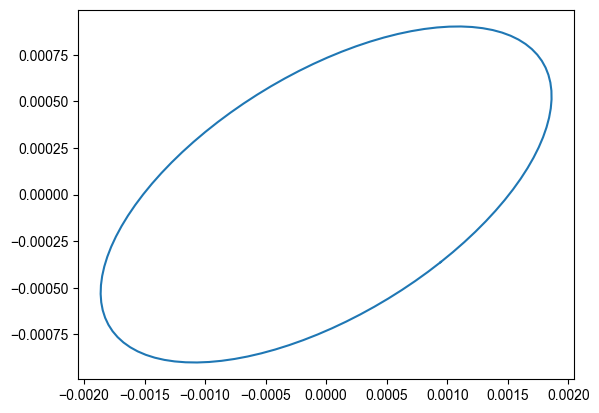

1.0
1.0



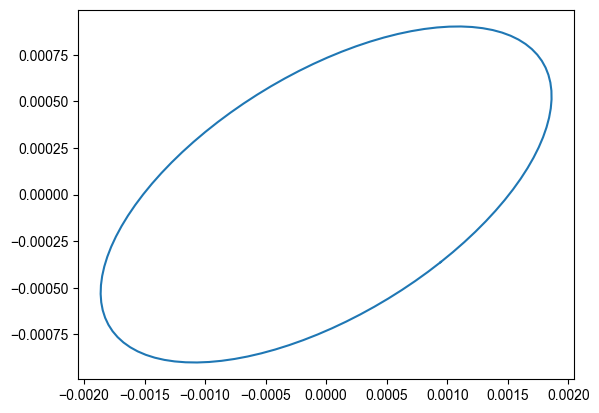

-1.0
-1.0



In [12]:
betax_mGBZ = solve_beta_x(E, thetay)

Jy_charge = np.sign((Jy * np.exp(-1j * thetay)).imag)
print("Jy charge", Jy_charge)
for betax in betax_mGBZ:
    r = abs(betax)
    thetax = np.log(betax).imag
    # 1. Get theoretical winding number
    dvxy_charge = np.sign(diff_vxy(
        E, r, thetax
    ).imag)
    theoretical_charge = -Jy_charge * dvxy_charge # For thetay, thetax

    # 2. Get numerical winding number
    epsilon = 1e-3
    t = np.linspace(0, 2 * np.pi, 100)
    thetay_list = thetay + epsilon * np.cos(t)
    thetax_list = thetax + epsilon * np.sin(t)
    betax_winding = r * np.exp(1j * thetax_list)
    betay_winding = gamma_y * np.exp(1j * thetay_list)
    ChP_val = ChP_xy(E, betax_winding, betay_winding)
    plt.plot(ChP_val.real, ChP_val.imag)
    plt.show()
    print(wGs.get_winding_number(ChP_val))
    print(theoretical_charge)
    print()

# [11]-strip

In [13]:
def ChP_11(E, beta_11, beta_y):
    return (
        E
        - Jx1 * beta_y / beta_11
        - Jx2 * beta_11 / beta_y
        - Jy1 / beta_y
        - Jy2 * beta_y
    )

In [14]:
def v11(r, theta_11):
    return (
        Jx1 * Jy1 / r * np.exp(-1j * theta_11)
        + Jx2 * Jy2 * r * np.exp(1j * theta_11)
        + Jx1 * Jx2
        + Jy1 * Jy2
    )

def diff_v11(r, theta_11):
    return (
        -1j* Jx1 * Jy1 / r * np.exp(-1j * theta_11)
        + 1j * Jx2 * Jy2 * r * np.exp(1j * theta_11)
    )

In [15]:
def solve_beta11(E, Delta_y):
    ''' Delta_y is defined as theta_y + varphi_11/2'''
    lhs = E ** 2 / 4 / (cos(Delta_y) ** 2)
    all_roots = np.roots(
        [Jx2 * Jy2,
         Jx1 * Jx2 + Jy1 * Jy2 - lhs,
         Jx1 * Jy1]
    )
    root_pair_list = []
    for beta_11 in all_roots:
        phi_11 = np.log(
            (Jx1 / beta_11 + Jy2)
            / (Jx2 * beta_11 + Jy1)
        ).imag
        theta_y_list = np.array([
            Delta_y - phi_11 / 2,
            Delta_y - phi_11 / 2 + pi
        ])
        beta_y_list = sqrt(abs(
            (Jx2 * beta_11 + Jy1) / (Jx1 / beta_11 + Jy2)
        )) * exp(1j * theta_y_list)
        val = abs(ChP_11(E, beta_11, beta_y_list))
        min_ind = np.argmin(val)
        root_pair_list.append((beta_11, theta_y_list[min_ind]))
    return root_pair_list


## Test derivative

In [16]:
# Test beta11 solutions
E = np.random.randn() + 1j * np.random.randn()
Delta_y = np.random.rand() * 2 * pi

all_roots = solve_beta11(E, Delta_y)
for beta_11, theta_y in all_roots:
    beta_y = sqrt(abs(
        (Jx2 * beta_11 + Jy1) / (Jx1 / beta_11 + Jy2)
    )) * exp(1j * theta_y)
    print(ChP_11(E, beta_11, beta_y))

(-7.771561172376096e-16-1.3322676295501878e-15j)
(-2.220446049250313e-16-8.604228440844963e-16j)


In [17]:
# test dv11
E = np.random.randn() + 1j * np.random.randn()
Delta_y = np.random.rand() * 2 * pi
dtheta_y = np.random.randn() * 1e-3
roots = solve_beta11(E, thetay)
for beta_11, theta_y in roots:
    r = abs(beta_11)
    theta_11 = np.log(betax).imag
    dthetax = np.random.randn() * 1e-4
    v2 = v11(r, thetax + dthetax)
    print(v2 - v11(r, thetax))
    print(diff_v11(r, thetax) * dthetax)
    print(abs(v2 - v11(r, thetax) - diff_v11(r, thetax) * dthetax))
    print()

(-0.0001742561994100278-0.00011459572488448089j)
(-0.00017425331551764706-0.00011459992866515844j)
5.097902239998583e-09

(-0.00013371721550670124+9.132841562120575e-06j)
(-0.0001337170309857492+9.134938810327356e-06j)
2.105349857526426e-09



In [18]:
# Test derivative
dtheta = np.random.randn() * 1e-3
# 1. Calculate betax for theta and theta + dtheta
betax1 = solve_beta11(E, Delta_y)
betax2 = solve_beta11(E, Delta_y + dtheta)

# 2. Match solutions by distance
distance_list = np.abs(
    [abs(betax2[j][0] - betax1[0][0]) for j in range(2)]
)
if np.argmin(distance_list) == 0:
    pass
else:
    betax2 = betax2[::-1]

thetay1 = [p[1] for p in betax1]
thetay2 = [p[1] for p in betax2]
deltay_list = np.array(thetay2) - np.array(thetay1)
betax1 = [p[0] for p in betax1]
betax2 = [p[0] for p in betax2]
print(betax1)
print(betax2)
# 3. Calculate derivative for theta
derivative_list = np.zeros(2)
for point_ind in range(2):
    # curr_betax = betax1[point_ind]
    # curr_r = abs(curr_betax)
    # curr_thetax = np.log(curr_betax).imag
    # C = (r ** 2) / (
    #     2 * np.abs(
    #         - Jx1 * Jy1 / r / exp(1j * curr_betax)
    #         + Jx2 * Jy2 * r * exp(1j * curr_betax)
    #     )**2 * cos(Delta_y) ** 2
    # )
    # thetay_term = np.tan(Delta_y)
    # diff_term = (E.conjugate() ** 2 * diff_v11(curr_r, curr_thetax)).imag
    # derivative_list[point_ind] = 2 * C * thetay_term * diff_term
    derivative_list[point_ind] = (
        (E**2 * r ** 2 * np.tan(Delta_y)) 
         / (
             2 *(
                 - Jx1 * Jy1 / betax1[point_ind]
                 + Jx2 * Jy2 * betax1[point_ind]
             )
         )
    ).real * 2
print(derivative_list)

print(deltay_list, dtheta)
# 4. Calculate numeric derivative
print(np.abs(betax2) ** 2 - np.abs(betax1) ** 2)
print(derivative_list * deltay_list)
print(np.abs(betax2) ** 2 - np.abs(betax1) ** 2 - derivative_list * dtheta)

[(-15900.888161046336+5507.016364216758j), (-8.987273122512328e-05-0.0002196360471197063j)]
[(-16049.033570524814+5558.3363443524495j), (-8.904296536750254e-05-0.00021760864011502264j)]
[ 0.00482247 -0.00482247]
[8.77127388e-05 8.96333310e-05] 8.867303489827356e-05
[ 5.30110792e+06 -1.03493108e-09]
[ 4.22992323e-07 -4.32254327e-07]
[5.30110792e+06 4.26588394e-07]


## Test topological charge

In [19]:
E = np.random.rand() + 1j * np.random.randn()
Dtheta_y = np.random.rand() * 2 * pi

In [20]:
all_sols = solve_beta11(E, Dtheta_y)
print(all_sols)

[((-1.8404094791939798+1.3257855482080907j), 7.055798757272952), ((-0.17145103701586872-1.7522105615019927j), 4.878664103375196)]


In [21]:
for beta_11, theta_y in all_sols:
    r = abs(beta_11)
    theta_11 = log(beta_11).imag
    epsilon = 1e-3
    t = np.linspace(0, 2 * pi, 1000)
    theta_11_loop = theta_11 + epsilon * sin(t)
    theta_y_loop = theta_y + epsilon * cos(t)
    beta_11_loop = r * exp(1j * theta_11_loop)
    beta_y_loop = sqrt(np.abs(
        (Jx2 * beta_11_loop + Jy1) /
        (Jx1 / beta_11_loop + Jy2)
    )) * exp(1j * theta_y_loop)
    f_val = ChP_11(E, beta_11_loop, beta_y_loop)
    print(wGs.get_winding_number(f_val))

    varphi_11 = log(
        (Jx2 * beta_11 + Jy1) /
        (Jx1 / beta_11 + Jy2)
    ).imag
    print(-tan(theta_y - varphi_11 / 2)
          * (diff_v11(r, theta_11) / v11(r, theta_11)).imag)

    theta_y2 = varphi_11 - theta_y
    theta_11_loop = theta_11 + epsilon * sin(t)
    theta_y_loop = theta_y2 + epsilon * cos(t)
    beta_11_loop = r * exp(1j * theta_11_loop)
    beta_y_loop = sqrt(np.abs(
        (Jx2 * beta_11_loop + Jy1) /
        (Jx1 / beta_11_loop + Jy2)
    )) * exp(1j * theta_y_loop)
    f_val = ChP_11(E, beta_11_loop, beta_y_loop)
    print(wGs.get_winding_number(f_val), abs(ChP_11(E, beta_11, sqrt(np.abs(
        (Jx2 * beta_11 + Jy1) /
        (Jx1 / beta_11 + Jy2)
    )) * exp(1j * theta_y2))))
    print()



0.9999999999999999
0.5349798227646477
-1.0 1.072098405376252e-15

-1.0
-0.534979822764652
1.0 9.930136612989092e-16



In [17]:
import numpy as np
class BIT:
    def __init__(self, size):
        self.size = size
        self.tree = [0] * (size + 1)

    def update(self, index, value=1):
        while index <= self.size:
            self.tree[index] += value
            index += index & -index

    def query(self, index):
        res = 0
        while index > 0:
            res += self.tree[index]
            index -= index & -index
        return res

def count_inversions(arr):
    # 离散化处理（如果数组元素不是连续的整数）
    sorted_arr = sorted(arr)
    rank = {num: i+1 for i, num in enumerate(sorted_arr)}

    bit = BIT(len(arr))
    inversion_count = 0

    for num in reversed(arr):
        r = rank[num]
        inversion_count += bit.query(r - 1)
        bit.update(r)

    return inversion_count

# 示例
arr = np.arange(100)
np.random.shuffle(arr)
print(arr)

[64 14 97 17 48 50 39 76 62 98 89 53 47  2 74 59 70 63 12 71 21 52 18 26
  7 11 56 34 30 15 42 54 29 19 31 32 96 38 91 25 61  4 90 43 94  9  0 68
  3 49  5 28 95 73 83 82 37 23 92 35 27 10 46 22 85 75 81 57 16 20 79 88
 66 51  1 45 44 67 24 77 41  6 55 58 36 87 78 99 80  8 86 72 84 69 60 40
 93 13 33 65]


In [8]:
def count_inversions_brute_force(arr):
    n = len(arr)
    inversion_count = 0
    for i in range(n):
        for j in range(i + 1, n):
            if arr[i] > arr[j]:
                inversion_count += 1
    return inversion_count

In [18]:
for _ in range(1000):
    count_inversions(arr)

In [19]:
for _ in range(1000):
    count_inversions_brute_force(arr)